**Proyecto Final: Clasificación de señales ECG**

**Integrantes:** Paula García · Valentina Morales

---

 **1. Revisión teórica del artículo**


**1.1 Resumen de la sección de extracción de características**

El artículo [1] explica cómo convertir una señal de ECG en un conjunto de números que un clasificador pueda usar. Primero comentan que había dos formas de hacerlo. La primera son las redes neuronales, que aprenden las características solas, pero necesitan muchos datos y mucho tiempo de cómputo, y no se puede saber qué característica usó la red. La segunda es medir amplitud, duración y distancia entre las ondas P, Q, T y el complejo QRS, pero esto no sirve bien en arritmias donde alguna onda se deforma o no aparece. También dicen que usar wavelet o FFT deja por fuera la información del tiempo.

Como paso previo, los autores reescalan cada señal para que su valor máximo sea 1 (algoritmo máximo-mínimo), con el fin de que la amplitud no dependa de la persona. Según sus resultados, esto mejoró muy poco la clasificación (el F1 sin reescalar fue solo 0.001 menor).

Su método consiste en detectar los picos y los valles de la señal sin importar a qué onda pertenecen, y medir tres cosas en cada uno: la altura, el ancho y la prominencia (cuánto sobresale un pico respecto a los picos vecinos). Los picos se separan en tres grupos (picos del QRS, otros picos y valles) y se comparan entre sí en seis combinaciones. Como cada paciente tiene un número distinto de picos, lo que hacen es construir una tabla de frecuencias con 100 intervalos entre el mínimo y el máximo de cada variable, de modo que todos los pacientes queden con el mismo número de características.

Además de esto, usan características más simples como la frecuencia ventricular, la duración del QRS, el intervalo QT, la media y la varianza de los intervalos R-R, la edad y el sexo. Con ellas arman 11 grupos de características (de 11 hasta 39,830 variables). El mejor resultado lo obtuvieron combinando los grupos de características simples con las de picos y valles (F1 ponderado de 0.988). Los histogramas de 100 intervalos usados solos dieron el peor resultado (0.887), lo que muestra que las características simples siguen siendo muy importantes.

**1.2 ¿Qué pasa cuando desaparecen ondas del complejo PQRS?**

El artículo [1] plantea que las características que miden una onda específica fallan cuando esa onda se distorsiona o desaparece. El ejemplo que dan es la fibrilación auricular (AFIB), donde la onda P es reemplazada por ondas de fibrilación más pequeñas y que no tienen relación con el QRS. En ese caso no se puede medir "la amplitud de la onda P" de forma confiable.

Para resolverlo, los autores no buscan ondas con nombre. Detectan todos los picos y valles de la señal y describen cómo se distribuyen con histogramas. Así, la ausencia de la onda P no genera un dato faltante, sino que aparece como un cambio en la distribución de picos y valles. También usan características que no dependen de ninguna onda en particular, como la media y la varianza de los intervalos R-R, porque solo necesitan detectar el QRS, que casi siempre está presente.

Esto conecta con lo que vimos en el Proyecto 1: AFIB fue el ritmo con mayor dispersión en fMP, algo coherente con un ritmo irregular y sin onda P bien definida.

---

**2. Base de datos**

Para este proyecto se descargó el archivo `ECGData.zip` de la misma colección de la base Chapman-Shaoxing del Proyecto 1. A diferencia de `ECGDataDenoised.zip`, este contiene las señales crudas, es decir, sin filtrar. Estas señales se filtran en el punto 3.

Se mantuvo el mismo subconjunto del Proyecto 1: los ritmos SB, SR, AFIB y ST en pacientes de 40 a 79 años, que suman 6.831 registros. Los ritmos y el rango de edad se justificaron en el punto 2.5 del Proyecto 1: son los ritmos con más registros, se incluye SR para tener ejemplos de un ECG normal, y se excluyen los menores de 40 y mayores de 80 años para que el modelo no asocie la edad con la arritmia. Como consecuencia, se dejan fuera 610 registros de AFIB de personas mayores de 80 años. No se excluyeron los pacientes con otras condiciones cardíacas registradas, porque son cerca de la mitad de los datos y quitarlos reduciría la muestra y la haría menos realista.


In [1]:
import zipfile
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm

RUTA_DIAGNOSTICS = Path("Diagnostics.xlsx")
ZIP_CRUDO = Path("ECGData.zip")      # señales crudas (sin filtrar)
FS = 500                             # Hz
N_MUESTRAS = 5000                    # 10 s a 500 Hz
DERIVACION = "II"                    # nombre de la columna de la derivación II
RITMOS_SEL = ["SB", "SR", "AFIB", "ST"]

# 1. Mismo subconjunto del Proyecto 1
df = pd.read_excel(RUTA_DIAGNOSTICS)
df_sel = df[df["Rhythm"].isin(RITMOS_SEL) & df["PatientAge"].between(40, 79)].copy()
print("Registros en el subconjunto:", len(df_sel))      # en el Proyecto 1 dio 6831

# 2. Leer la derivación II cruda de cada registro, directo desde el zip
z = zipfile.ZipFile(ZIP_CRUDO)
indice = {Path(n).stem: n for n in z.namelist() if n.lower().endswith(".csv")}
print("Archivos CSV dentro del zip:", len(indice))

senales, problemas = {}, []
for fn in tqdm(df_sel["FileName"]):
    if fn not in indice:
        problemas.append((fn, "no está en el zip")); continue
    with z.open(indice[fn]) as f:
        x = pd.read_csv(f, usecols=[DERIVACION], encoding="utf-8-sig")[DERIVACION].to_numpy(dtype=float)
    if len(x) != N_MUESTRAS:
        problemas.append((fn, f"longitud {len(x)}"))
    elif not np.isfinite(x).all():
        problemas.append((fn, "tiene NaN o infinitos"))
    elif np.ptp(x) == 0:
        problemas.append((fn, "señal constante"))
    else:
        senales[fn] = x

# 3. Resumen de lo que se descarta y por qué
df_prob = pd.DataFrame(problemas, columns=["FileName", "motivo"]).merge(
    df_sel[["FileName", "Rhythm"]], on="FileName")
print("Señales válidas:", len(senales), "| descartadas:", len(df_prob))
display(df_prob["motivo"].value_counts())
display(df_prob["Rhythm"].value_counts())

# 4. Guardar el subconjunto válido y la matriz de señales crudas (derivación II)
df_ok = df_sel[df_sel["FileName"].isin(senales)].reset_index(drop=True)
X_crudo = np.vstack([senales[fn] for fn in df_ok["FileName"]]).astype(np.float32)
df_ok.to_csv("subconjunto_proyecto2.csv", index=False)
np.save("X_crudo_derivacion2.npy", X_crudo)
print("Matriz guardada:", X_crudo.shape)

Registros en el subconjunto: 6831
Archivos CSV dentro del zip: 10646


100%|██████████| 6831/6831 [02:19<00:00, 48.96it/s]

Señales válidas: 6831 | descartadas: 0


Series([], Name: count, dtype: int64)

Series([], Name: count, dtype: int64)

Matriz guardada: (6831, 5000)


De cada registro se usó solo la derivación II, como pide el enunciado. Antes de continuar se revisó que cada señal estuviera en el archivo, tuviera 5.000 muestras (10 s a 500 Hz), no tuviera valores faltantes y no fuera una línea plana. Todas las señales cumplieron estas revisiones, por lo que se conservaron los 6.831 registros: 3.298 de SB, 1.374 de SR, 1.162 de AFIB y 997 de ST.

---

**3. Filtrado de las señales**

**3.1 Flujo de filtrado**

El flujo de filtrado se tomó del artículo de la base de datos [2], que aplica tres pasos en orden sobre la señal cruda:

1. **Filtro pasabajas Butterworth.** Elimina el ruido de alta frecuencia (ruido muscular, interferencia de la red eléctrica y ruido aleatorio). Siguiendo el artículo, se pidió una banda de paso hasta 50 Hz y una banda de rechazo desde 60 Hz, con máximo 1 dB de rizado en la banda de paso y al menos 2,5 dB de atenuación en la de rechazo. Con estos valores el filtro resultante es de orden 3. Se aplicó hacia adelante y hacia atrás sobre la señal, para compensar el retraso que introduce el filtro y no desplazar las ondas.

2. **LOESS robusto.** Estima la línea base (la oscilación lenta causada, por ejemplo, por la respiración, por debajo de 0,5 Hz) ajustando en cada punto un polinomio local que da más peso a los puntos cercanos. La versión robusta le da peso cero a los puntos muy alejados, de modo que los picos del QRS no arrastren la tendencia. Esa tendencia se resta a la señal. El artículo no indica el tamaño de la ventana, por lo que se eligió una ventana de 2 segundos, mayor que el período de un latido, y se verificó visualmente que la tendencia no sigue las ondas del latido.

3. **Non-Local Means (NLM).** Elimina el ruido que queda. Cada punto se reemplaza por un promedio ponderado de los puntos de la señal cuyo entorno se parece al suyo, aprovechando que los latidos se repiten. Se usaron los parámetros del artículo de Zheng et al. [1]: parche de 10 muestras, búsqueda en toda la señal y parámetro de suavizado igual a 1,5 veces la desviación estándar del ruido, estimada con la desviación absoluta mediana (MAD).


**Programación del flujo de filtrado**

En la siguiente celda se programan los tres pasos del filtrado y una función que los aplica en orden (`filtrar_senal`). Los parámetros tomados del artículo se definen al inicio, y el tamaño de la ventana del LOESS, que el artículo no indica, se fijó en 2 segundos. El filtro Butterworth se calcula con la función `buttord` a partir de las frecuencias y atenuaciones del artículo, y al ejecutar la celda se imprime el orden y la frecuencia de corte obtenidos.

In [2]:
import numpy as np
import pandas as pd
from scipy import signal
from statsmodels.nonparametric.smoothers_lowess import lowess

FS = 500                       # Hz
# --- Parámetros del artículo (Zheng et al., Sci. Data 2020 y Sci. Rep. 2020) ---
F_PASO, F_STOP = 50, 60        # Hz: Butterworth pasabajas, banda de paso hasta 50 Hz y de rechazo desde 60 Hz
RIZADO_DB, ATEN_DB = 1.0, 2.5  # dB: máximo rizado en la banda de paso y mínima atenuación en la de rechazo
PARCHE = 10                    # NLM: tamaño del parche (muestras)
K_LAMBDA = 1.5                 # NLM: lambda = 1.5 * sigma del ruido
# --- Parámetro que el artículo no da y elegimos nosotros ---
FRAC_LOESS = 0.2               # fracción de la señal usada en cada ajuste local (0.2 de 10 s = 2 s)

ORDEN, WN = signal.buttord(F_PASO, F_STOP, RIZADO_DB, ATEN_DB, fs=FS)
SOS = signal.butter(ORDEN, WN, btype="low", fs=FS, output="sos")

def paso1_butterworth(x):
    """Pasabajas Butterworth aplicado hacia adelante y hacia atrás (fase cero)."""
    return signal.sosfiltfilt(SOS, x)

def paso2_linea_base(x, frac=FRAC_LOESS):
    """LOESS robusto: estima la línea base y se la resta a la señal."""
    t = np.arange(len(x)) / FS
    tendencia = lowess(x, t, frac=frac, it=3, delta=0.05, return_sorted=False)
    return x - tendencia, tendencia

def sigma_ruido(x):
    """Desviación estándar del ruido con MAD (ecuación 5 del artículo)."""
    D = (2 * x[1:-1] - x[:-2] - x[2:]) / np.sqrt(6)
    return 1.4826 * np.median(np.abs(D - np.median(D)))

def paso3_nlm(x, parche=PARCHE, k_lambda=K_LAMBDA, bloque=500):
    """Non-Local Means: cada punto se reemplaza por un promedio ponderado de todos los
    puntos cuyo parche se parece al suyo (peso gaussiano)."""
    n = len(x)
    lam = k_lambda * sigma_ruido(x)
    xp = np.pad(x, (parche // 2, parche - parche // 2 - 1), mode="reflect")
    P = np.lib.stride_tricks.sliding_window_view(xp, parche).astype(np.float32)
    sq = (P ** 2).sum(axis=1)
    y = np.empty(n)
    for a in range(0, n, bloque):
        b = min(a + bloque, n)
        d2 = sq[a:b, None] + sq[None, :] - 2 * P[a:b] @ P.T      # distancia al cuadrado entre parches
        w = np.exp(-np.maximum(d2, 0) / (2 * parche * lam ** 2))
        y[a:b] = (w @ x) / w.sum(axis=1)
    return y

def filtrar_senal(x):
    """Flujo completo: Butterworth -> LOESS robusto -> NLM."""
    x = np.asarray(x, dtype=float)
    y = paso1_butterworth(x)
    y, _ = paso2_linea_base(y)
    return paso3_nlm(y)

print(f"Butterworth: orden {ORDEN}, frecuencia de corte {WN:.1f} Hz")

Butterworth: orden 3, frecuencia de corte 61.5 Hz


**3.2 Validación con la señal filtrada de la base de datos**


En esta celda se toma un registro de cada ritmo (SB, SR, ST y AFIB) y se leen tres versiones de la misma señal: la cruda (`ECGData.zip`), la filtrada de la base de datos (`ECGDataDenoised.zip`, la del Proyecto 1) y la filtrada con el código anterior. Para cada registro se grafican las tres versiones en el tiempo y su densidad espectral (método de Welch), y al final se calculan la correlación y el error cuadrático medio (RMSE) entre la señal filtrada por nosotros y la de la base, junto con el número de picos R y la relación de amplitud del pico R.

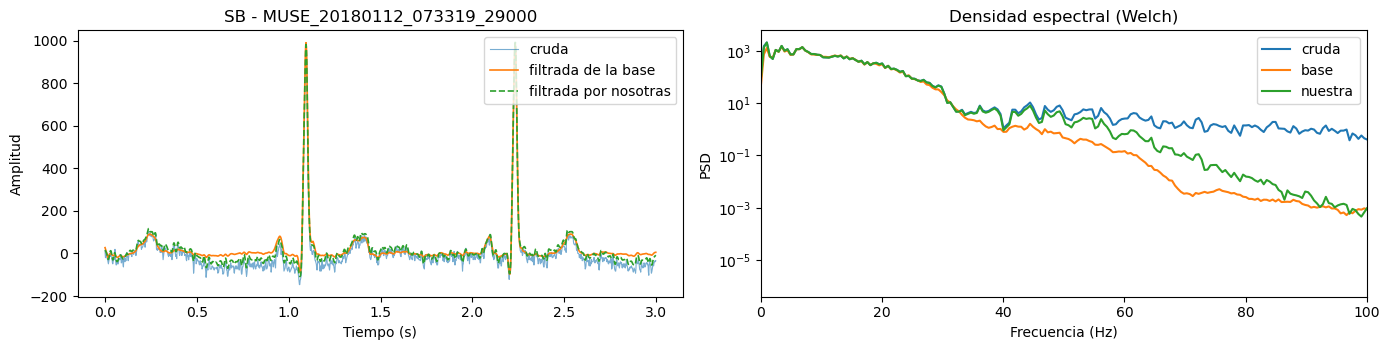

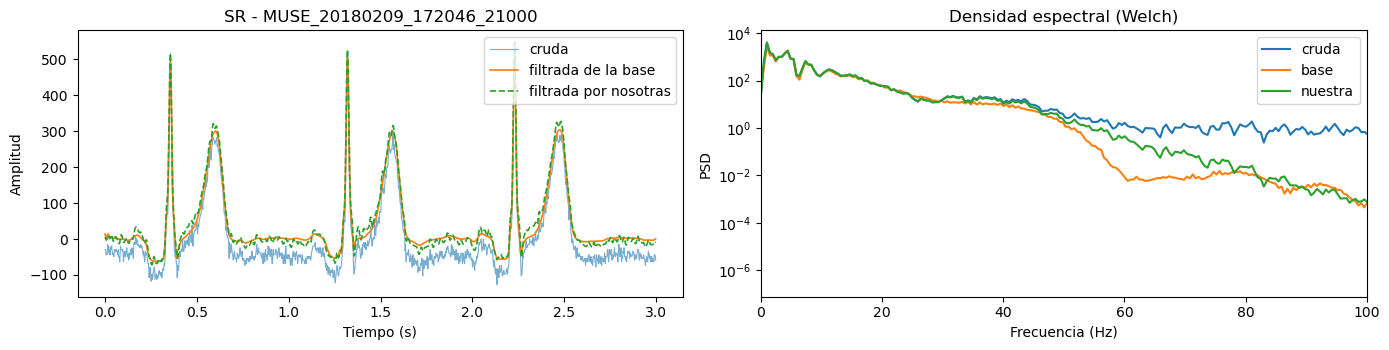

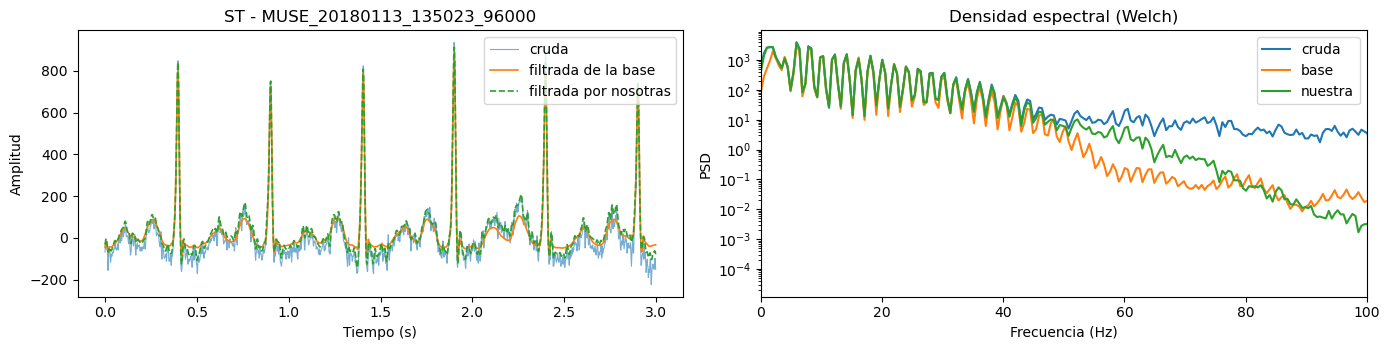

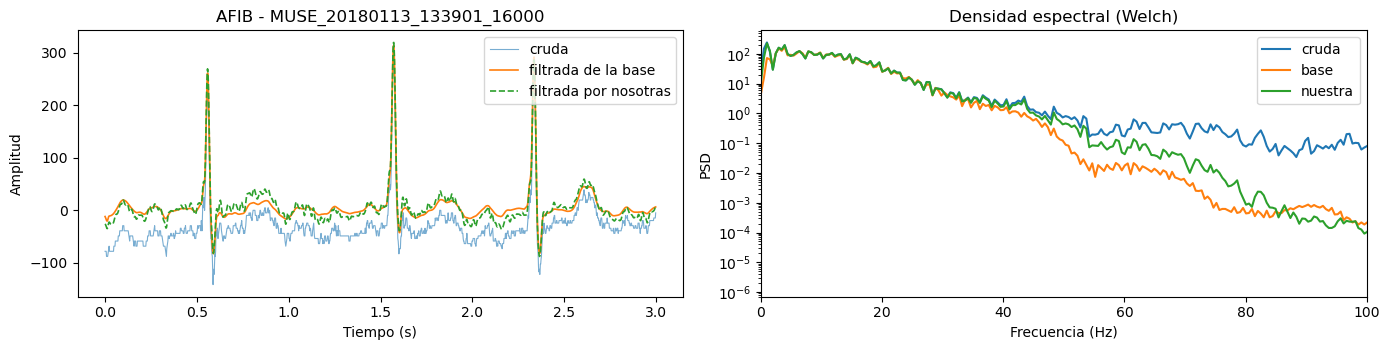

,Ritmo,FileName,"corr(nuestra, base)","RMSE(nuestra, base)","RMSE(cruda, base)",picos R cruda/base/nuestra,amp. R nuestra / base
0,SB,MUSE_20180112_073319_29000,0.981,23.967,38.417,8/8/8,1.000
1,SR,MUSE_20180209_172046_21000,0.987,16.853,42.241,14/13/14,1.039
2,ST,MUSE_20180113_135023_96000,0.968,38.753,57.780,20/20/20,1.027
3,AFIB,MUSE_20180113_133901_16000,0.958,12.587,29.818,12/12/12,1.001


In [3]:
import zipfile
import matplotlib.pyplot as plt
from pathlib import Path

ZIP_CRUDO = Path("ECGData.zip")
ZIP_DENOISED = Path("ECGDataDenoised.zip")

df_ok = pd.read_csv("subconjunto_proyecto2.csv")

zc = zipfile.ZipFile(ZIP_CRUDO)
idx_c = {Path(n).stem: n for n in zc.namelist() if n.lower().endswith(".csv")}
zd = zipfile.ZipFile(ZIP_DENOISED)
idx_d = {Path(n).stem: n for n in zd.namelist() if n.lower().endswith(".csv")}

def leer_cruda(fn):
    """Señal cruda, derivación II (los archivos crudos tienen encabezado)."""
    with zc.open(idx_c[fn]) as f:
        return pd.read_csv(f, usecols=["II"], encoding="utf-8-sig")["II"].to_numpy(float)

def leer_denoised(fn):
    """Señal filtrada de la base, derivación II (estos archivos no tienen encabezado)."""
    with zd.open(idx_d[fn]) as f:
        return pd.read_csv(f, header=None, usecols=[1]).iloc[:, 0].to_numpy(float)

def picos_r(x):
    return signal.find_peaks(x, height=0.5 * x.max(), distance=int(0.25 * FS))[0]

# un registro de cada ritmo
ejemplos = df_ok.groupby("Rhythm").head(1)
filas = []
for _, r in ejemplos.iterrows():
    fn = r["FileName"]
    x, d = leer_cruda(fn), leer_denoised(fn)
    y = filtrar_senal(x)

    t = np.arange(len(x)) / FS
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
    ax[0].plot(t[:1500], x[:1500], lw=.8, alpha=.6, label="cruda")
    ax[0].plot(t[:1500], d[:1500], lw=1.2, label="filtrada de la base")
    ax[0].plot(t[:1500], y[:1500], lw=1.2, ls="--", label="filtrada por nosotras")
    ax[0].set(title=f"{r['Rhythm']} - {fn}", xlabel="Tiempo (s)", ylabel="Amplitud")
    ax[0].legend(loc="upper right")
    for s, nom in ((x, "cruda"), (d, "base"), (y, "nuestra")):
        f_, P = signal.welch(s, FS, nperseg=1024)
        ax[1].semilogy(f_, P, label=nom)
    ax[1].set(xlim=(0, 100), xlabel="Frecuencia (Hz)", ylabel="PSD")
    ax[1].legend(); ax[1].set_title("Densidad espectral (Welch)")
    plt.tight_layout(); plt.show()

    pk_x, pk_d, pk_y = picos_r(x), picos_r(d), picos_r(y)
    filas.append({"Ritmo": r["Rhythm"], "FileName": fn,
                  "corr(nuestra, base)": np.corrcoef(y, d)[0, 1],
                  "RMSE(nuestra, base)": np.sqrt(np.mean((y - d) ** 2)),
                  "RMSE(cruda, base)": np.sqrt(np.mean((x - d) ** 2)),
                  "picos R cruda/base/nuestra": f"{len(pk_x)}/{len(pk_d)}/{len(pk_y)}",
                  "amp. R nuestra / base": np.median(y[picos_r(y)]) / np.median(d[picos_r(d)])})
display(pd.DataFrame(filas).round(3))

En el tiempo, la señal filtrada por nosotros coincide con la de la base: la correlación fue de 0,96 a 0,99 y el pico R mantuvo su posición y su altura (relación de amplitud de 1,00 a 1,03). Además, el error cuadrático medio (RMSE) respecto a la base bajó en las cuatro señales al pasar de la señal cruda a la filtrada por nosotros (por ejemplo, en SR de 42,2 a 16,9 y en AFIB de 29,8 a 12,6), es decir, nuestro filtro acerca la señal a la de la base.

En el espectro, las tres señales coinciden por debajo de unos 40 Hz, que es donde está la información del ECG. Entre 40 y 80 Hz la señal cruda conserva mucho ruido, y las dos filtradas lo reducen, pero la de la base lo reduce más que la nuestra (aproximadamente un orden de magnitud). Esto se explica porque el artículo describe el filtro pero no da todos los parámetros ni el código usado, por lo que no se puede reproducir exactamente. Esta diferencia no afecta las características que se usan en este trabajo (fMP y sFSB), que trabajan con frecuencias de hasta 20 Hz, donde las curvas coinciden.

También se observó que el filtrado reduce un poco los picos y suaviza el detalle fino de la señal. Por ejemplo, en AFIB la señal de la base es más lisa entre latidos que la nuestra, lo cual puede quitar ruido pero también parte de la actividad de fibrilación. Esto concuerda con que los filtros mejoran la relación señal-ruido pero introducen distorsión.



**3.3 Aplicación del filtrado a todas las señales**


Una vez validado el filtro, en la siguiente celda se aplica a las 6.831 señales del subconjunto que se guardaron en el punto 2. Como el proceso es largo (el paso NLM compara cada punto con todos los demás), las señales se procesan en bloques de 250, usando 4 procesos en paralelo, y cada bloque se guarda en la carpeta `partes_filtradas`; de esta forma, si la ejecución se interrumpe, se puede retomar sin repetir lo ya hecho. Al final se unen todos los bloques en una sola matriz (`X_filtrado_derivacion2.npy`) y se comprueba que no haya valores faltantes.

In [4]:
import time, os
from pathlib import Path
from joblib import Parallel, delayed

X_crudo = np.load("X_crudo_derivacion2.npy", mmap_mode="r")      # (6831, 5000), sin cargar todo en RAM
N = len(X_crudo)
TAM_BLOQUE = 250                                                  # señales por bloque
N_NUCLEOS = 4                                                     # procesos en paralelo (los núcleos físicos)
DIR_PARTES = Path("partes_filtradas"); DIR_PARTES.mkdir(exist_ok=True)

t0 = time.time()
for ini in range(0, N, TAM_BLOQUE):
    archivo = DIR_PARTES / f"parte_{ini:05d}.npy"
    if archivo.exists():                                          # si ya se hizo, se salta (permite retomar)
        continue
    fin = min(ini + TAM_BLOQUE, N)
    res = Parallel(n_jobs=N_NUCLEOS)(delayed(filtrar_senal)(np.array(X_crudo[i])) for i in range(ini, fin))
    np.save(archivo, np.vstack(res).astype(np.float32))
    print(f"{fin}/{N} señales | {(time.time() - t0) / 60:.1f} min", flush=True)

X_filtrado = np.vstack([np.load(DIR_PARTES / f"parte_{ini:05d}.npy") for ini in range(0, N, TAM_BLOQUE)])
np.save("X_filtrado_derivacion2.npy", X_filtrado)
assert X_filtrado.shape == (N, 5000) and np.isfinite(X_filtrado).all()
print("Listo:", X_filtrado.shape)

750/6831 señales | 3.4 min
1000/6831 señales | 6.7 min
1250/6831 señales | 9.6 min
1500/6831 señales | 12.6 min
1750/6831 señales | 15.6 min
2000/6831 señales | 18.9 min
2250/6831 señales | 22.3 min
2500/6831 señales | 25.9 min
2750/6831 señales | 29.5 min
3000/6831 señales | 33.3 min
3250/6831 señales | 36.5 min
3500/6831 señales | 39.7 min
3750/6831 señales | 42.7 min
4000/6831 señales | 45.9 min
4250/6831 señales | 49.1 min
4500/6831 señales | 52.0 min
4750/6831 señales | 55.1 min
5000/6831 señales | 58.0 min
5250/6831 señales | 61.0 min
5500/6831 señales | 64.2 min
5750/6831 señales | 67.4 min
6000/6831 señales | 70.6 min
6250/6831 señales | 73.5 min
6500/6831 señales | 76.7 min
6750/6831 señales | 79.6 min
6831/6831 señales | 80.7 min
Listo: (6831, 5000)


El filtrado se aplicó a las 6.831 señales del subconjunto (derivación II) y tardó aproximadamente 81 minutos. El resultado se guardó en un archivo para usarlo en los puntos siguientes, y todas las señales filtradas tienen valores finitos.


---


**4. Conjunto de características**

Para clasificar usamos las dos características del proyecto 1 y les sumamos las que se discutieron en el punto 1, que salen del artículo de Zheng et al. [1].

**4.1 Características elegidas y justificación**

| Característica | Qué mide | De dónde sale | Por qué la usamos |
|---|---|---|---|
| fMP | Frecuencia con mayor potencia en el espectro (0,3 a 20 Hz) | Proyecto 1 (Kotriwar et al.) | Resume el contenido en frecuencia de toda la señal sin depender de ninguna onda en particular |
| sFSB | Número de frecuencias acopladas en fase con la fMP (bicoherencia) | Proyecto 1 (Kotriwar et al.) | Mide acoplamiento no lineal entre frecuencias y tampoco depende de ondas específicas |
| RR medio | Promedio de los intervalos entre picos R (ms) | Características simples del artículo (media de R-R) [1] | SB, SR y ST se definen por la frecuencia cardíaca (menos de 60, entre 60 y 100, y más de 100 lpm) [3] |
| SDNN | Desviación estándar de los intervalos R-R | Varianza de R-R del artículo [1] (SDNN es su raíz) y variabilidad de la frecuencia cardíaca [3][4] | En la fibrilación auricular los R-R son irregulares [5] |
| RMSSD | Raíz de la media de las diferencias sucesivas entre R-R al cuadrado | Variabilidad de la frecuencia cardíaca [3][4] | Mide la variabilidad latido a latido, por lo que es sensible a la irregularidad |
| n_RR | Número de intervalos R-R detectados en la señal | Conteo de R-R del artículo [1] | Está relacionado con la frecuencia cardíaca; se revisa si es redundante con RR medio |
| n_picos | Número de picos de la señal | Picos y valles del artículo [1] | Resume la forma de la señal sin identificar a qué onda corresponde cada pico |
| prom_picos | Prominencia media de los picos | Picos y valles del artículo [1] | Igual que la anterior, y además da una idea de la amplitud de las deflexiones |
| prom_valles | Prominencia media de los valles | Picos y valles del artículo [1] | Igual que la anterior, para las deflexiones negativas |

El artículo plantea que las características que dependen de una onda concreta (P, Q, T) funcionan mal cuando esa onda se distorsiona o desaparece por la enfermedad, como pasa con la onda P en la fibrilación auricular [1]. Por eso evitamos medir ondas individuales. Las características R-R solo necesitan localizar el complejo QRS, y fMP, sFSB y las de picos y valles se calculan sobre toda la señal. El artículo usa los picos y valles sin decir a qué onda corresponden, y nosotras tomamos una versión simplificada de esa idea: el número de picos y su prominencia media, sin las tablas de frecuencias de 100 intervalos del artículo.


**4.2 Detección de los picos R**

Para calcular las características R-R detectamos los picos R de cada señal filtrada con la librería NeuroKit2 [6]. Comparamos cuatro métodos de la librería con la frecuencia ventricular que viene en Diagnostics.xlsx. El método neurokit fue el que mejor coincidió: error mediano de 0,29 lpm y 93,7 % de las señales dentro de ±5 lpm, frente a entre 37 % y 58 % de los otros tres (pantompkins1985, elgendi2010 y hamilton2002, usados con sus parámetros por defecto). Por eso usamos neurokit.

Con este método 133 señales (1,9 %) quedaron con un error mayor a 10 lpm, sobre todo en frecuencias altas (donde se saltan latidos) y en bradicardia sinusal (donde cuenta también la onda T). Dejamos esas señales en el conjunto y lo tomamos como una limitación de las características R-R. Diez señales no tuvieron suficientes intervalos R-R detectados y se excluyeron, por lo que el conjunto final tiene 6821 señales (SB 3292, SR 1373, AFIB 1161 y ST 995).

In [10]:
import neurokit2 as nk


FS = 500
X_filtrado = np.load("X_filtrado_derivacion2.npy")
df_ok = pd.read_csv("subconjunto_proyecto2.csv")

def picos_r(y, fs=FS, metodo="neurokit"):
    """Posiciones (en muestras) de los picos R."""
    return nk.ecg_peaks(y, sampling_rate=fs, method=metodo)[1]["ECG_R_Peaks"]

def caract_rr(y):
    """Características de los intervalos R-R (en ms). Necesita al menos 3 intervalos."""
    r = picos_r(y)
    rr = np.diff(r) / FS * 1000
    if len(rr) < 3:
        return dict(n_RR=len(rr), RR_medio=np.nan, SDNN=np.nan, RMSSD=np.nan, FC_est=np.nan)
    return dict(n_RR=len(rr),
                RR_medio=rr.mean(),
                SDNN=rr.std(ddof=1),
                RMSSD=np.sqrt(np.mean(np.diff(rr) ** 2)),
                FC_est=60000 / rr.mean())

nulo = dict(n_RR=np.nan, RR_medio=np.nan, SDNN=np.nan, RMSSD=np.nan, FC_est=np.nan)
filas = []
for i in tqdm(range(len(X_filtrado))):
    try:
        filas.append(caract_rr(np.asarray(X_filtrado[i], dtype=float)))
    except Exception:
        filas.append(nulo)
df_rr = pd.DataFrame(filas)
print("Señales sin características:", int(df_rr["RR_medio"].isna().sum()))

# --- Validación: frecuencia estimada vs frecuencia ventricular de Diagnostics ---
diag = pd.read_excel("Diagnostics.xlsx")[["FileName", "VentricularRate"]]
val = df_ok[["FileName", "Rhythm"]].merge(diag, on="FileName", how="left")
val["FC_est"] = df_rr["FC_est"].to_numpy()
val["error"] = val["FC_est"] - val["VentricularRate"]

ea = val["error"].abs()
print(f"Error absoluto mediano: {ea.median():.2f} lpm")
print(f"Dentro de ±5 lpm: {100*(ea <= 5).sum()/ea.notna().sum():.1f} % | "
      f"dentro de ±10 lpm: {100*(ea <= 10).sum()/ea.notna().sum():.1f} %")
print("Señales con error > 10 lpm:", int((ea > 10).sum()))

100%|██████████| 6831/6831 [00:29<00:00, 229.27it/s]


Señales sin características: 10
Error absoluto mediano: 0.29 lpm
Dentro de ±5 lpm: 93.9 % | dentro de ±10 lpm: 98.1 %
Señales con error > 10 lpm: 133


**Comparación de detectores**

In [11]:
FC_ref = val["VentricularRate"].to_numpy(dtype=float)

def fc_con_metodo(y, metodo):
    try:
        r = nk.ecg_peaks(y, sampling_rate=FS, method=metodo)[1]["ECG_R_Peaks"]
        rr = np.diff(r) / FS * 1000
        return 60000 / rr.mean() if len(rr) >= 3 else np.nan
    except Exception:
        return np.nan

filas = []
for m in ["neurokit", "pantompkins1985", "hamilton2002", "elgendi2010"]:
    fc = np.array([fc_con_metodo(np.asarray(X_filtrado[i], dtype=float), m)
                   for i in tqdm(range(len(X_filtrado)), desc=m)])
    err = np.abs(fc - FC_ref)
    filas.append({"detector": m,
                  "sin resultado": int(np.isnan(fc).sum()),
                  "error mediano": np.nanmedian(err),
                  "% ±5 lpm": 100 * np.nanmean(err <= 5),
                  "% ±10 lpm": 100 * np.nanmean(err <= 10)})
print(pd.DataFrame(filas).round(2))

elgendi2010: 100%|██████████| 6831/6831 [03:32<00:00, 32.18it/s]

          detector  sin resultado  error mediano  % ±5 lpm  % ±10 lpm
0         neurokit             10           0.29     93.73      97.91
1  pantompkins1985              1           4.14     58.21      77.38
2     hamilton2002              1          11.27     37.08      48.00
3      elgendi2010              0           3.50     52.25      65.28


**4.3 Cálculo de las características y dataframe de trabajo**

En la siguiente celda calculamos las demás características sobre las señales filtradas del punto 3. La fMP y la sFSB se calculan con las mismas funciones del proyecto 1: se quita la tendencia con un polinomio de grado 5, se comprime la señal al rango [0, 1], se usan segmentos de 500 muestras (N = 10, umbral de bicoherencia de 0,678) y un rango de 0,3 a 20 Hz. Los picos y valles se detectan con find_peaks de SciPy sobre la señal filtrada, y de ahí sacamos el número de picos y la prominencia media de picos y de valles. Luego unimos estas características con las R-R en un dataframe con las columnas Registro, Estado y las nueve características, y sacamos las señales sin características R-R.

In [12]:
from scipy import signal

L = 500            # muestras por segmento: N = 10, umbral = 0.678 (igual que en el proyecto 1)
FMIN, FMAX = 0.3, 20
GRADO_DETREND = 5

# --- Funciones del proyecto 1 (fMP y sFSB) ---
def quitar_tendencia(x, n=GRADO_DETREND):
    tt = np.arange(len(x))
    return x - np.polynomial.Polynomial.fit(tt, x, n)(tt)

def comprimir(x):
    return (x - x.min()) / (x.max() - x.min())

def umbral_bicoherencia(N):
    return np.sqrt(9.2 / (2 * N))

def bicoherencia(x, fs=FS, L=L, fmax=FMAX):
    N = len(x) // L
    X = np.fft.fft(x[:N * L].reshape(N, L), axis=1)
    k = np.arange(1, int(fmax * L / fs) + 1)
    K1, K2 = np.meshgrid(k, k, indexing="ij")
    prod = X[:, K1] * X[:, K2] * np.conj(X[:, K1 + K2])
    num = np.abs(prod.sum(axis=0))
    den = np.abs(prod).sum(axis=0)
    B = np.divide(num, den, out=np.zeros_like(num), where=den > 0)
    return k * fs / L, B, N

def fmp_senal(x, fs=FS, fmin=FMIN, fmax=FMAX):
    f = np.fft.rfftfreq(len(x), d=1 / fs)
    P = np.abs(np.fft.rfft(x)) ** 2 / len(x)
    zona = (f >= fmin) & (f <= fmax)
    return f[zona][np.argmax(P[zona])]

def sfsb_senal(x, fm, fs=FS, L=L, fmax=FMAX):
    f, B, N = bicoherencia(x, fs, L, fmax)
    i = np.argmin(np.abs(f - fm))
    validas = (f + f[i]) <= fmax
    return int(np.sum((B[i, :] > umbral_bicoherencia(N)) & validas))

# --- Picos y valles (artículo, punto 1) ---
def caract_picos(y):
    pk, prop_p = signal.find_peaks(y, prominence=0)
    vl, prop_v = signal.find_peaks(-y, prominence=0)
    pp = prop_p["prominences"].mean() if len(pk) else np.nan
    pv = prop_v["prominences"].mean() if len(vl) else np.nan
    return len(pk), pp, pv

# --- Calcular sobre las señales filtradas ---
filas = []
for i in tqdm(range(len(X_filtrado))):
    y = np.asarray(X_filtrado[i], dtype=float)
    s = comprimir(quitar_tendencia(y))
    fm = fmp_senal(s)
    n_pk, pp, pv = caract_picos(y)
    filas.append({"fMP": fm, "sFSB": sfsb_senal(s, fm),
                  "n_picos": n_pk, "prom_picos": pp, "prom_valles": pv})

# --- Dataframe de trabajo: Registro | Estado | características ---
df_car = pd.concat(
    [df_ok[["FileName", "Rhythm"]].rename(columns={"FileName": "Registro", "Rhythm": "Estado"}).reset_index(drop=True),
     df_rr[["RR_medio", "SDNN", "RMSSD", "n_RR"]].reset_index(drop=True),
     pd.DataFrame(filas)], axis=1)
df_car = df_car[["Registro", "Estado", "fMP", "sFSB", "RR_medio", "SDNN", "RMSSD",
                 "n_RR", "n_picos", "prom_picos", "prom_valles"]]

antes = len(df_car)
df_car = df_car.dropna().reset_index(drop=True)      # quita las señales sin características R-R
print(f"Excluidas por falta de características: {antes - len(df_car)} | quedan {len(df_car)}")
print(df_car["Estado"].value_counts().to_dict())
display(df_car.head())

# --- Revisión ---
caract = [c for c in df_car.columns if c not in ("Registro", "Estado")]
display(df_car.groupby("Estado")[caract].median().round(2))

corr = df_car[caract].corr()
alta = [(a, b, round(corr.loc[a, b], 2)) for j, a in enumerate(caract)
        for b in caract[j + 1:] if abs(corr.loc[a, b]) > 0.9]
print("Pares con |correlación| > 0.9:", alta)

# --- Comparación con el proyecto 1 ---
p1 = pd.read_csv("resultados_fmp_sfsb.csv")
c = df_car.merge(p1, on="Registro", suffixes=("", "_p1"))
print(f"fMP igual al P1 en {100*np.isclose(c['fMP'], c['fMP_p1']).mean():.1f} % | "
      f"sFSB igual al P1 en {100*(c['sFSB'] == c['sFSB_p1']).mean():.1f} % ({len(c)} registros)")

df_car.to_csv("dataframe_caracteristicas.csv", index=False)

100%|██████████| 6831/6831 [00:33<00:00, 204.50it/s]

Excluidas por falta de características: 10 | quedan 6821
{'SB': 3292, 'SR': 1373, 'AFIB': 1161, 'ST': 995}


,Registro,Estado,fMP,sFSB,RR_medio,SDNN,RMSSD,n_RR,n_picos,prom_picos,prom_valles
0,MUSE_20180112_073319_29000,SB,0.9,19,1160.571429,28.582379,49.362604,7,397,45.193865,42.918381
1,MUSE_20180113_121940_44000,SB,0.9,19,1125.750000,17.838562,26.338456,8,420,33.764892,32.042977
2,MUSE_20180112_120347_79000,SB,3.8,16,1059.500000,26.005494,40.000000,8,333,39.306652,37.110125
3,MUSE_20180209_172046_21000,SR,4.2,14,947.000000,25.582112,39.597980,10,320,42.112878,41.148329
4,MUSE_20180114_075128_92000,SB,1.0,19,1025.555556,51.708585,71.933998,9,314,53.600307,50.860746


,fMP,sFSB,RR_medio,SDNN,RMSSD,n_RR,n_picos,prom_picos,prom_valles
Estado,,,,,,,,,
AFIB,3.1,14.0,663.71,134.72,187.85,14.0,343.0,62.12,61.03
SB,1.0,17.0,1064.25,24.64,31.21,8.0,359.0,46.85,45.24
SR,3.5,15.0,814.18,14.24,15.10,11.0,345.0,60.97,59.68
ST,5.2,12.0,556.62,5.35,4.69,16.0,322.0,91.33,90.08


Pares con |correlación| > 0.9: [('RR_medio', 'n_RR', np.float64(-0.96)), ('SDNN', 'RMSSD', np.float64(0.97)), ('prom_picos', 'prom_valles', np.float64(1.0))]
fMP igual al P1 en 71.9 % | sFSB igual al P1 en 50.0 % (6821 registros)


**4.4 Resultados y selección final**

Con las nueve características calculadas, el dataframe quedó con 6821 señales (SB 3292, SR 1373, AFIB 1161 y ST 995). Estas son las medianas por ritmo:

| Característica | AFIB | SB | SR | ST |
|---|---|---|---|---|
| fMP (Hz) | 3,1 | 1,0 | 3,5 | 5,2 |
| sFSB | 14 | 17 | 15 | 12 |
| RR medio (ms) | 663,7 | 1064,3 | 814,2 | 556,6 |
| SDNN (ms) | 134,7 | 24,6 | 14,2 | 5,4 |
| RMSSD (ms) | 187,9 | 31,2 | 15,1 | 4,7 |
| n_RR | 14 | 8 | 11 | 16 |
| n_picos | 343 | 359 | 345 | 322 |
| prom_picos | 62,1 | 46,9 | 61,0 | 91,3 |
| prom_valles | 61,0 | 45,2 | 59,7 | 90,1 |

El RR medio ordena los ritmos por frecuencia cardíaca (ST el más corto, SB el más largo), como se espera por su definición [3]. El SDNN y el RMSSD son mucho mayores en AFIB, que es lo que se espera de un ritmo con intervalos R-R irregulares [5]. El número de picos casi no cambia entre ritmos, y la prominencia solo separa un poco ST de SB, mientras AFIB y SR quedan parecidas.

Al calcular la correlación entre características encontramos tres pares con |r| mayor a 0,9: RR medio y n_RR (−0,96), SDNN y RMSSD (0,97), y prom_picos y prom_valles (1,00). Son pares que miden casi lo mismo (n_RR es aproximadamente 10 s dividido entre el RR medio, el SDNN y el RMSSD miden la irregularidad, y los picos y valles se alternan en la señal, por lo que sus prominencias son casi iguales). Como tener características tan parecidas no aporta información nueva, dejamos una de cada par: RR medio (se interpreta directamente como frecuencia cardíaca), SDNN (corresponde a la varianza de R-R del artículo [1]) y prom_picos. El conjunto final tiene seis características (fMP, sFSB, RR medio, SDNN, n_picos y prom_picos).

También comparamos la fMP y la sFSB con las que calculamos en el proyecto 1 con las señales de la base ya filtradas. Coinciden solo en el 71,9 % (fMP) y el 50,0 % (sFSB) de los registros. No analizamos a fondo la causa. Es posible que la fMP cambie de un armónico a otro cuando dos picos del espectro tienen potencia parecida, y que la sFSB cambie al depender de la fMP y de un umbral muy sensible a pequeños cambios de la señal. Otra posible fuente de diferencia es que el artículo no da el tamaño de la ventana para quitar la línea base, y elegimos el nuestro. Estas son hipótesis que no comprobamos.

In [13]:
df_car = df_car.drop(columns=["n_RR", "RMSSD", "prom_valles"])
df_car.to_csv("dataframe_caracteristicas.csv", index=False)
print(df_car.shape, list(df_car.columns))

(6821, 8) ['Registro', 'Estado', 'fMP', 'sFSB', 'RR_medio', 'SDNN', 'n_picos', 'prom_picos']


**4.5 Resumen del punto 4**

El dataframe de trabajo (`dataframe_caracteristicas.csv`) tiene 6821 señales de la derivación II ya filtradas, una por fila, con las columnas Registro, Estado y seis características: fMP y sFSB (del proyecto 1), RR medio y SDNN (variabilidad de los intervalos R-R) y n_picos y prom_picos (picos y valles del artículo [1]). Este es el dataframe que usamos en los puntos siguientes. La principal limitación es que alrededor del 2 % de las señales tienen características R-R poco confiables por errores en la detección de los picos R.

---


**5. Red neuronal para las cuatro patologías**

**5.1 Diseño de la red y justificación**

Para clasificar SB, SR, AFIB y ST usamos una red neuronal densa (perceptrón multicapa), que es la red que se usa normalmente cuando cada ejemplo es una lista de números, como en nuestro dataframe, donde cada señal quedó resumida en seis características [10]. Usamos la librería scikit-learn [8]. En las capas internas usamos la activación ReLU, que deja pasar los valores positivos y anula los negativos, y en la salida la función softmax, que convierte las salidas en cuatro probabilidades que suman 1. La red se entrena minimizando la entropía cruzada con el optimizador Adam [9, 10].

Los datos se separaron en 70 % para entrenamiento, 15 % para validación y 15 % para prueba, manteniendo la proporción de cada ritmo en los tres conjuntos. Las características se escalaron con la media y la desviación estándar del conjunto de entrenamiento únicamente, para que la información de validación y de prueba no se filtre al entrenamiento (material del curso, Unidad IA/ML/DL). La validación se usó para comparar las arquitecturas y la prueba solo para el reporte final.

Las clases están desbalanceadas (SB tiene más de tres veces las señales de ST). Por eso, durante el entrenamiento se dio más peso a las clases con menos señales, y para evaluar usamos la precisión, el recall y el F1 de cada clase, además de la exactitud, que sola puede engañar cuando hay desbalance [11]. Para detener el entrenamiento a tiempo se usó parada temprana, que corta cuando el error deja de mejorar en datos apartados [10].

Probamos tres arquitecturas: A, con una capa de 16 neuronas; B, con dos capas (64 y 32); y C, con tres capas (128, 64 y 32) y una penalización L2 más fuerte, que limita el tamaño de los pesos para reducir el sobreajuste [10]. scikit-learn no tiene dropout, por eso usamos L2 como regularización. Hay que tener en cuenta que C cambia la profundidad, el ancho y la regularización a la vez, por lo que no se puede separar el efecto de cada cambio.

Entrenamiento: 4774 | Validación: 1023 | Prueba: 1024
{'SB': 2304, 'SR': 961, 'AFIB': 813, 'ST': 696}


,Parámetros,Épocas,Exactitud val,F1 macro val,Exactitud prueba,F1 macro prueba
Arquitectura,,,,,,
A: (16),180,140,0.922,0.908,0.937,0.922
"B: (64, 32)",2660,94,0.947,0.938,0.943,0.930
"C: (128, 64, 32)",11364,59,0.947,0.937,0.943,0.929


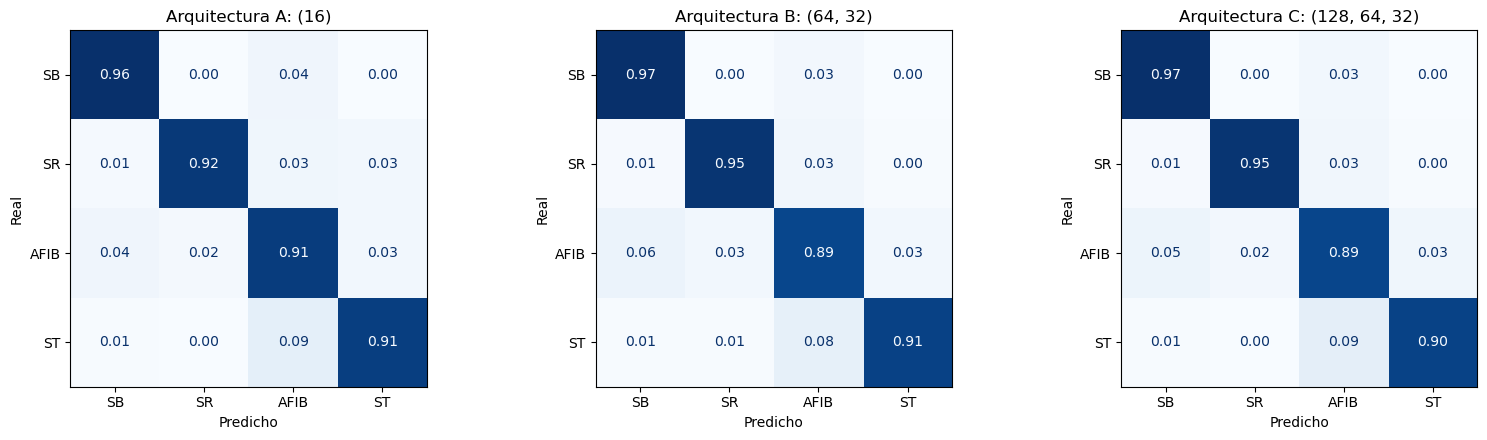


=== Arquitectura A: (16) ===
              precision    recall  f1-score   support

          SB      0.977     0.960     0.968       494
          SR      0.979     0.922     0.950       206
        AFIB      0.803     0.914     0.855       174
          ST      0.925     0.907     0.916       150

    accuracy                          0.937      1024
   macro avg      0.921     0.926     0.922      1024
weighted avg      0.940     0.937     0.938      1024

Matriz de confusión (conteos; filas = real, columnas = predicho):
       SB   SR  AFIB   ST
SB    474    1    19    0
SR      3  190     7    6
AFIB    7    3   159    5
ST      1    0    13  136

=== Arquitectura B: (64, 32) ===
              precision    recall  f1-score   support

          SB      0.974     0.972     0.973       494
          SR      0.966     0.951     0.958       206
        AFIB      0.828     0.885     0.856       174
          ST      0.958     0.907     0.932       150

    accuracy                     

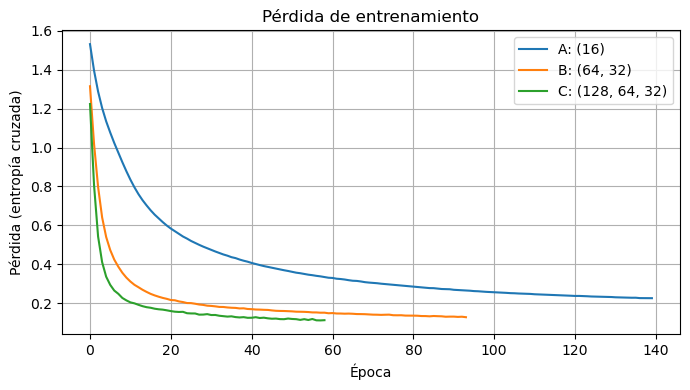

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, accuracy_score)

SEMILLA = 42
CLASES = ["SB", "SR", "AFIB", "ST"]
CARACT = ["fMP", "sFSB", "RR_medio", "SDNN", "n_picos", "prom_picos"]
CODIGOS = list(range(len(CLASES)))     # SB=0, SR=1, AFIB=2, ST=3 (con texto, la parada temprana falla)

# --- 1. Separar en entrenamiento (70 %), validación (15 %) y prueba (15 %), estratificado ---
X = df_car[CARACT].to_numpy()
y = df_car["Estado"].map({c: i for i, c in enumerate(CLASES)}).to_numpy()

X_ent, X_tmp, y_ent, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
X_val, X_pru, y_val, y_pru = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEMILLA)
print("Entrenamiento:", len(y_ent), "| Validación:", len(y_val), "| Prueba:", len(y_pru))
print(dict(zip(CLASES, pd.Series(y_ent).value_counts().reindex(CODIGOS).tolist())))

# --- 2. Escalar: se ajusta SOLO con entrenamiento ---
escalador = StandardScaler().fit(X_ent)
X_ent_s, X_val_s, X_pru_s = (escalador.transform(a) for a in (X_ent, X_val, X_pru))

# --- 3. Pesos por clase (para compensar el desbalance) ---
pesos = compute_sample_weight("balanced", y_ent)

# --- 4. Tres arquitecturas ---
ARQUITECTURAS = {
    "A: (16)":           dict(hidden_layer_sizes=(16,),         alpha=1e-4),
    "B: (64, 32)":       dict(hidden_layer_sizes=(64, 32),      alpha=1e-4),
    "C: (128, 64, 32)":  dict(hidden_layer_sizes=(128, 64, 32), alpha=1e-2),
}

modelos, filas = {}, []
for nombre, params in ARQUITECTURAS.items():
    m = MLPClassifier(activation="relu", solver="adam", max_iter=500,
                      early_stopping=True, validation_fraction=0.1, n_iter_no_change=15,
                      random_state=SEMILLA, **params)
    m.fit(X_ent_s, y_ent, sample_weight=pesos)
    modelos[nombre] = m
    n_par = sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)
    p_val, p_pru = m.predict(X_val_s), m.predict(X_pru_s)
    filas.append({"Arquitectura": nombre, "Parámetros": n_par, "Épocas": m.n_iter_,
                  "Exactitud val": accuracy_score(y_val, p_val),
                  "F1 macro val": f1_score(y_val, p_val, average="macro"),
                  "Exactitud prueba": accuracy_score(y_pru, p_pru),
                  "F1 macro prueba": f1_score(y_pru, p_pru, average="macro")})
resumen = pd.DataFrame(filas).set_index("Arquitectura")
display(resumen.round(3))

# --- 5. Matrices de confusión en prueba (cada fila suma 1: fracción de cada ritmo real) ---
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nombre, m) in zip(axs, modelos.items()):
    ConfusionMatrixDisplay.from_predictions(y_pru, m.predict(X_pru_s), labels=CODIGOS,
                                            display_labels=CLASES,
                                            normalize="true", values_format=".2f",
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Arquitectura {nombre}")
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

# --- 6. Reporte por clase (precisión, recall y F1) en prueba ---
for nombre, m in modelos.items():
    print(f"\n=== Arquitectura {nombre} ===")
    print(classification_report(y_pru, m.predict(X_pru_s), labels=CODIGOS, target_names=CLASES, digits=3))
    print("Matriz de confusión (conteos; filas = real, columnas = predicho):")
    print(pd.DataFrame(confusion_matrix(y_pru, m.predict(X_pru_s), labels=CODIGOS),
                       index=CLASES, columns=CLASES))

# --- 7. Pérdida de entrenamiento por época ---
plt.figure(figsize=(7, 4))
for nombre, m in modelos.items():
    plt.plot(m.loss_curve_, label=nombre)
plt.xlabel("Época"); plt.ylabel("Pérdida (entropía cruzada)")
plt.title("Pérdida de entrenamiento"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

**5.2 Resultados y análisis**

| Arquitectura | Parámetros | Épocas | Exactitud val | F1 macro val | Exactitud prueba | F1 macro prueba |
|---|---|---|---|---|---|---|
| A: (16) | 180 | 140 | 0,922 | 0,908 | 0,937 | 0,922 |
| B: (64, 32) | 2660 | 94 | 0,947 | 0,938 | 0,943 | 0,930 |
| C: (128, 64, 32) | 11364 | 59 | 0,947 | 0,937 | 0,943 | 0,929 |

Las tres redes clasificaron bien: la exactitud en prueba fue de 0,937 a 0,943 y el F1 macro de 0,922 a 0,930. La arquitectura A, la más pequeña, tuvo el menor desempeño en validación (F1 macro de 0,908 frente a 0,938 y 0,937). Pasar de B a C, con cuatro veces más parámetros, no mejoró nada: con 1024 señales de prueba, una diferencia de 0,001 en el F1 equivale a muy pocas señales, por lo que no la consideramos real. Escogimos B como la mejor red porque tuvo el F1 macro más alto en validación y es más simple que C. Con solo seis características, una red pequeña parece ser suficiente.

Con los reportes por clase se ve que el ritmo más difícil es AFIB: tiene un recall aceptable (0,885 a 0,914), pero la precisión más baja (0,803 a 0,828), y por eso su F1 (alrededor de 0,85) es el menor de los cuatro ritmos. SB, SR y ST tuvieron F1 entre 0,916 y 0,974. La baja precisión de AFIB viene de falsas AFIB: en la red B, 13 SB, 12 ST y 7 SR fueron clasificadas como AFIB, y en las otras dos redes el patrón es parecido. SB y SR casi no se confunden entre sí (entre 0 y 3 señales), lo cual es esperable porque esos ritmos se definen por la frecuencia cardíaca y el RR medio ya la contiene [3]. En la sección 5.3 revisamos las SB clasificadas como AFIB, que son la mayor fuente de falsas AFIB.

La pérdida de entrenamiento bajó en las tres redes, más rápido en C (59 épocas) y más lento en A (140 épocas). Esta curva es solo del entrenamiento, así que no permite concluir si hubo sobreajuste.

Como limitaciones, usamos una sola separación de los datos y una sola semilla, por lo que las diferencias pequeñas entre arquitecturas no son concluyentes. Además, la arquitectura C cambia la profundidad, el ancho y la regularización al mismo tiempo, así que no sabemos cuál de esos cambios influyó en su resultado.


**5.3 Revisión de las SB clasificadas como AFIB**

La mayor fuente de falsas AFIB fueron señales SB (13 en la red B). Para entender por qué, en la siguiente celda comparamos, para esas 13 señales, la frecuencia estimada con la de referencia y el SDNN. En la celda que sigue graficamos las 6 con mayor SDNN con los picos R que detectó el programa.

In [19]:
# ¿Las SB clasificadas como AFIB son señales con latidos mal detectados?
idx = np.arange(len(df_car))
i_ent, i_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEMILLA)
i_val, i_pru = train_test_split(i_tmp, test_size=0.50, stratify=y_tmp, random_state=SEMILLA)

pred = modelos["B: (64, 32)"].predict(X_pru_s)
cuales = i_pru[(y_pru == 0) & (pred == 2)]        # SB reales clasificadas como AFIB

sub = (df_car.loc[cuales, ["Registro", "RR_medio", "SDNN"]]
       .merge(val[["FileName", "VentricularRate", "FC_est", "error"]],
              left_on="Registro", right_on="FileName"))
print("SB clasificadas como AFIB:", len(sub))
print("De ellas, con error de frecuencia > 10 lpm:", int((sub["error"].abs() > 10).sum()))
display(sub[["Registro", "VentricularRate", "FC_est", "error", "RR_medio", "SDNN"]].round(1))

SB clasificadas como AFIB: 13
De ellas, con error de frecuencia > 10 lpm: 5


,Registro,VentricularRate,FC_est,error,RR_medio,SDNN
0,MUSE_20180118_131742_83000,57,68.2,11.2,879.6,278.3
1,MUSE_20180113_183742_87000,43,85.7,42.7,700.2,315.8
2,MUSE_20180112_071540_45000,53,72.8,19.8,824.5,291.7
3,MUSE_20180112_170850_77000,59,61.3,2.3,978.7,123.0
4,MUSE_20180120_121012_82000,59,66.0,7.0,908.6,211.7
5,MUSE_20180113_135447_15000,59,65.4,6.4,917.8,218.3
6,MUSE_20180112_165750_92000,58,60.9,2.9,985.6,138.5
7,MUSE_20180116_131252_68000,56,70.2,14.2,854.8,284.6
8,MUSE_20180120_123723_19000,57,64.0,7.0,938.2,230.6
9,MUSE_20180113_125046_50000,59,65.8,6.8,911.2,215.3


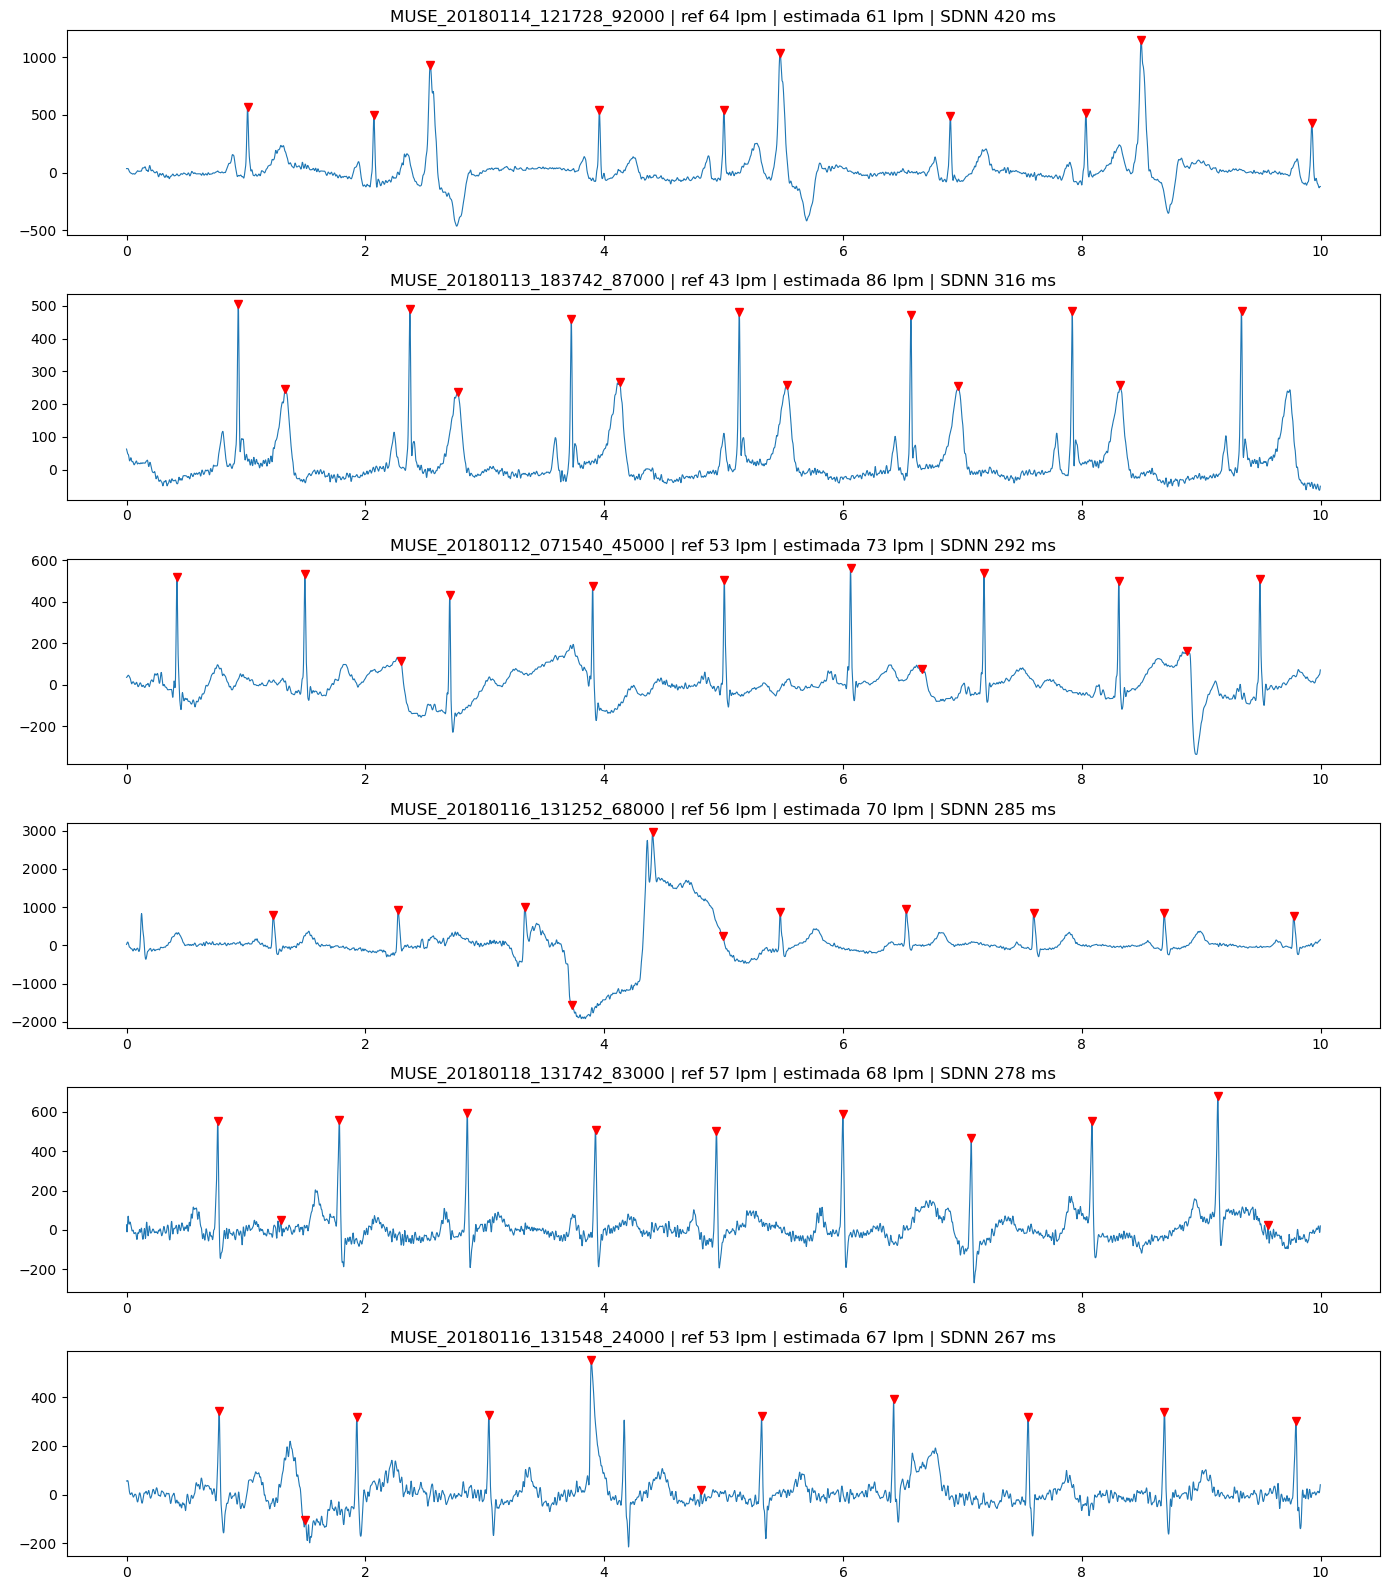

In [20]:
orden = sub.sort_values("SDNN", ascending=False).head(6)
fig, axs = plt.subplots(6, 1, figsize=(14, 16))
for ax, (_, f) in zip(axs, orden.iterrows()):
    i = df_ok.index[df_ok["FileName"] == f["Registro"]][0]
    y_ = np.asarray(X_filtrado[i], dtype=float)
    r = picos_r(y_)
    t_ = np.arange(len(y_)) / FS
    ax.plot(t_, y_, lw=0.8)
    ax.plot(r / FS, y_[r], "rv")
    ax.set_title(f"{f['Registro']} | ref {f['VentricularRate']:.0f} lpm | "
                 f"estimada {f['FC_est']:.0f} lpm | SDNN {f['SDNN']:.0f} ms")
plt.tight_layout()
plt.show()

Solo 5 de las 13 SB tenían un error de frecuencia mayor a 10 lpm, pero todas tenían un SDNN muy alto (entre 123 y 420 ms, frente a una mediana de 24,6 ms en las SB), es decir, intervalos R-R irregulares que la red asocia con AFIB. En las 6 señales con mayor SDNN, en 5 el detector marcó entre 1 y 3 picos de más sobre artefactos, saltos de la línea base o pequeñas ondas (incluida una onda T), lo que parte un intervalo en dos y sube mucho el SDNN. En la sexta los latidos sí estaban bien detectados, pero algunos llegaban antes de tiempo y con otra forma, lo que sugiere irregularidad real del ritmo. Esto muestra que el SDNN es muy sensible a un solo pico falso. Una posible mejora sería usar una medida de variabilidad más robusta a valores extremos, que no probamos. Revisamos solo 6 de las 13 señales, por lo que esta conclusión vale para ellas.

**5.4 Resumen del punto 5**

La mejor red fue la arquitectura B (dos capas de 64 y 32 neuronas), con una exactitud de 0,943 y un F1 macro de 0,930 en prueba. La clase más difícil fue AFIB (F1 de alrededor de 0,85), sobre todo por su baja precisión, y parte de esos errores se explica por picos R mal detectados en señales SB, que hacen que el SDNN suba y parezcan irregulares. Esta red es la que usamos como referencia para comparar con XGBoost en el punto 7.


---

**6. Red neuronal para dos de las cuatro patologías**

**6.1 Elección de los ritmos y diseño**

Para este punto elegimos SR (ritmo sinusal normal) y AFIB (fibrilación auricular). Distinguir un ritmo normal de una fibrilación auricular es el problema que abordan trabajos de detección automática como el de Tateno y Glass [5], y es la pregunta clínica más directa que podría contestar un dispositivo: ¿el ritmo es normal o hay fibrilación? Tomamos AFIB como la clase positiva, es decir, la que queremos detectar, y SR como la negativa.

Del dataframe del punto 4 nos quedamos solo con las señales de esos dos ritmos (SR 1373 y AFIB 1161) y las separamos igual que en el punto 5: 70 % para entrenamiento, 15 % para validación y 15 % para prueba, con la misma proporción de cada ritmo, escalando las características con los datos de entrenamiento únicamente. Como las dos clases están casi balanceadas, el desbalance es mucho menor que en el punto 5, pero igual usamos pesos por clase para mantener el mismo procedimiento. Con dos clases, la red tiene una sola salida con función sigmoide, que da la probabilidad de que la señal sea AFIB [10].

Probamos las mismas tres arquitecturas del punto 5 (A con 16 neuronas, B con 64 y 32, y C con 128, 64 y 32 y una penalización L2 más fuerte), para poder comparar con aquel resultado. Además de la exactitud, usamos la sensibilidad (de las AFIB reales, qué fracción detecta la red), la especificidad (de las SR reales, qué fracción descarta correctamente), el F1 de AFIB y el área bajo la curva ROC (AUC), que mide qué tan bien separa la red las dos clases sin depender de un umbral [11].



Señales: 2534 | SR: 1373 | AFIB: 1161
Entrenamiento: 1773 | Validación: 380 | Prueba: 381


,Parámetros,Épocas,Exactitud val,F1 AFIB val,Exactitud prueba,Sensibilidad,Especificidad,F1 AFIB prueba,AUC prueba
Arquitectura,,,,,,,,,
A: (16),129,50,0.968,0.965,0.953,0.943,0.961,0.948,0.975
"B: (64, 32)",2561,31,0.984,0.983,0.974,0.994,0.956,0.972,0.975
"C: (128, 64, 32)",11265,20,0.979,0.977,0.969,0.983,0.956,0.966,0.972


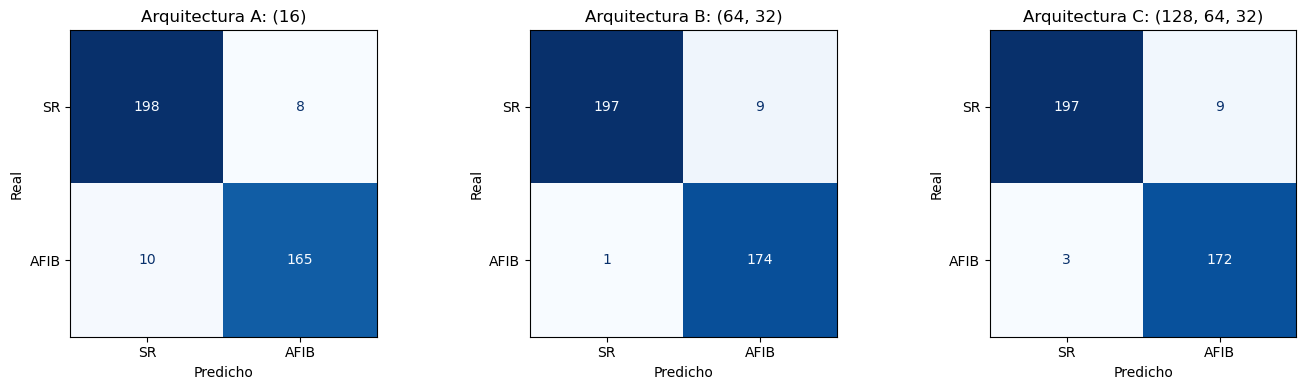


=== Arquitectura A: (16) ===
              precision    recall  f1-score   support

          SR      0.952     0.961     0.957       206
        AFIB      0.954     0.943     0.948       175

    accuracy                          0.953       381
   macro avg      0.953     0.952     0.952       381
weighted avg      0.953     0.953     0.953       381

SR bien: 198 | SR como AFIB (falsos positivos): 8 | AFIB como SR (falsos negativos): 10 | AFIB bien: 165

=== Arquitectura B: (64, 32) ===
              precision    recall  f1-score   support

          SR      0.995     0.956     0.975       206
        AFIB      0.951     0.994     0.972       175

    accuracy                          0.974       381
   macro avg      0.973     0.975     0.974       381
weighted avg      0.975     0.974     0.974       381

SR bien: 197 | SR como AFIB (falsos positivos): 9 | AFIB como SR (falsos negativos): 1 | AFIB bien: 174

=== Arquitectura C: (128, 64, 32) ===
              precision    recall 

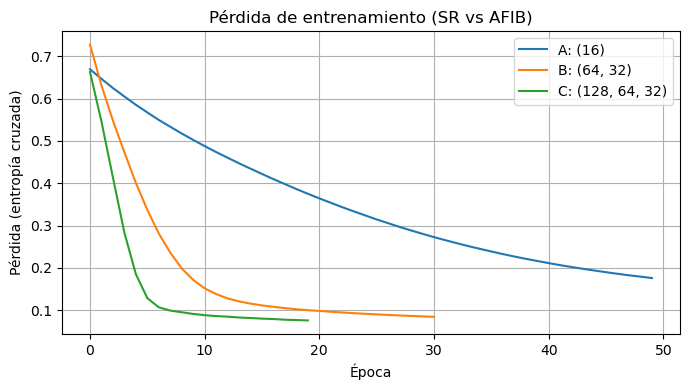

In [22]:
SEMILLA = 42
CLASES2 = ["SR", "AFIB"]                       # SR = 0 (negativa), AFIB = 1 (positiva)
CARACT = ["fMP", "sFSB", "RR_medio", "SDNN", "n_picos", "prom_picos"]

# --- 1. Quedarse solo con SR y AFIB y separar en entrenamiento / validación / prueba ---
df2 = df_car[df_car["Estado"].isin(CLASES2)]
X2 = df2[CARACT].to_numpy()
y2 = df2["Estado"].map({c: i for i, c in enumerate(CLASES2)}).to_numpy()
print("Señales:", len(y2), "| SR:", int((y2 == 0).sum()), "| AFIB:", int((y2 == 1).sum()))

X_ent2, X_tmp2, y_ent2, y_tmp2 = train_test_split(X2, y2, test_size=0.30, stratify=y2, random_state=SEMILLA)
X_val2, X_pru2, y_val2, y_pru2 = train_test_split(X_tmp2, y_tmp2, test_size=0.50, stratify=y_tmp2, random_state=SEMILLA)
print("Entrenamiento:", len(y_ent2), "| Validación:", len(y_val2), "| Prueba:", len(y_pru2))

# --- 2. Escalar (ajustado solo con entrenamiento) y pesos por clase ---
esc2 = StandardScaler().fit(X_ent2)
X_ent2s, X_val2s, X_pru2s = (esc2.transform(a) for a in (X_ent2, X_val2, X_pru2))
pesos2 = compute_sample_weight("balanced", y_ent2)

# --- 3. Las mismas tres arquitecturas del punto 5 ---
ARQUITECTURAS = {
    "A: (16)":           dict(hidden_layer_sizes=(16,),         alpha=1e-4),
    "B: (64, 32)":       dict(hidden_layer_sizes=(64, 32),      alpha=1e-4),
    "C: (128, 64, 32)":  dict(hidden_layer_sizes=(128, 64, 32), alpha=1e-2),
}

modelos2, filas = {}, []
for nombre, params in ARQUITECTURAS.items():
    m = MLPClassifier(activation="relu", solver="adam", max_iter=500,
                      early_stopping=True, validation_fraction=0.1, n_iter_no_change=15,
                      random_state=SEMILLA, **params)
    m.fit(X_ent2s, y_ent2, sample_weight=pesos2)
    modelos2[nombre] = m
    n_par = sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)
    pv, pp = m.predict(X_val2s), m.predict(X_pru2s)
    filas.append({"Arquitectura": nombre, "Parámetros": n_par, "Épocas": m.n_iter_,
                  "Exactitud val": accuracy_score(y_val2, pv),
                  "F1 AFIB val": f1_score(y_val2, pv),
                  "Exactitud prueba": accuracy_score(y_pru2, pp),
                  "Sensibilidad": recall_score(y_pru2, pp, pos_label=1),
                  "Especificidad": recall_score(y_pru2, pp, pos_label=0),
                  "F1 AFIB prueba": f1_score(y_pru2, pp),
                  "AUC prueba": roc_auc_score(y_pru2, m.predict_proba(X_pru2s)[:, 1])})
resumen2 = pd.DataFrame(filas).set_index("Arquitectura")
pd.set_option("display.max_columns", None)
display(resumen2.round(3))

# --- 4. Matrices de confusión 2x2 en prueba (conteos) ---
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nombre, m) in zip(axs, modelos2.items()):
    ConfusionMatrixDisplay.from_predictions(y_pru2, m.predict(X_pru2s), display_labels=CLASES2,
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Arquitectura {nombre}")
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

# --- 5. Reporte por clase ---
for nombre, m in modelos2.items():
    print(f"\n=== Arquitectura {nombre} ===")
    print(classification_report(y_pru2, m.predict(X_pru2s), target_names=CLASES2, digits=3))
    tn, fp, fn, tp = confusion_matrix(y_pru2, m.predict(X_pru2s)).ravel()
    print(f"SR bien: {tn} | SR como AFIB (falsos positivos): {fp} | "
          f"AFIB como SR (falsos negativos): {fn} | AFIB bien: {tp}")

# --- 6. Pérdida de entrenamiento por época ---
plt.figure(figsize=(7, 4))
for nombre, m in modelos2.items():
    plt.plot(m.loss_curve_, label=nombre)
plt.xlabel("Época"); plt.ylabel("Pérdida (entropía cruzada)")
plt.title("Pérdida de entrenamiento (SR vs AFIB)"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

**6.2 Resultados y análisis**

| Arquitectura | Parámetros | Épocas | Exactitud val | F1 AFIB val | Exactitud prueba | Sensibilidad | Especificidad | F1 AFIB prueba | AUC prueba |
|---|---|---|---|---|---|---|---|---|---|
| A: (16) | 129 | 50 | 0,968 | 0,965 | 0,953 | 0,943 | 0,961 | 0,948 | 0,975 |
| B: (64, 32) | 2561 | 31 | 0,984 | 0,983 | 0,974 | 0,994 | 0,956 | 0,972 | 0,975 |
| C: (128, 64, 32) | 11265 | 20 | 0,979 | 0,977 | 0,969 | 0,983 | 0,956 | 0,966 | 0,972 |

Matrices de confusión en prueba (381 señales: 206 SR y 175 AFIB):

| Arquitectura | SR bien | SR como AFIB (falsa alarma) | AFIB como SR (no detectada) | AFIB bien |
|---|---|---|---|---|
| A: (16) | 198 | 8 | 10 | 165 |
| B: (64, 32) | 197 | 9 | 1 | 174 |
| C: (128, 64, 32) | 197 | 9 | 3 | 172 |

Las tres redes separan bien SR de AFIB: la exactitud en prueba fue de 0,953 a 0,974 y el AUC de 0,972 a 0,975. Como el AUC es casi igual en las tres, su capacidad para separar las dos clases es parecida, y las diferencias están sobre todo en cómo reparten los errores. La arquitectura A cometió 8 falsas alarmas y dejó sin detectar 10 AFIB, la B cometió 9 y 1, y la C cometió 9 y 3. La B tuvo el mayor F1 de AFIB en validación (0,983) y la mayor exactitud (0,974) y sensibilidad (0,994) en prueba, por lo que la consideramos la mejor. Sin embargo, la diferencia con A y C es de pocas señales (18, 10 y 12 errores en 381), así que no es concluyente.

Si se piensa en un dispositivo que avise de una fibrilación, es más grave no detectar una AFIB que dar una falsa alarma, y en ese sentido la B es la más conveniente (solo 1 de 175 AFIB sin detectar). Con las SR, las tres redes cometieron entre 8 y 9 falsas alarmas (especificidad de 0,956 a 0,961). Es posible que parte de esas falsas alarmas se deba a picos R falsos que suben el SDNN, como vimos en la sección 5.3, pero no lo comprobamos.

Al comparar con el punto 5, AFIB tuvo un F1 de alrededor de 0,85 con cuatro clases (precisión de 0,80 a 0,83) y aquí tiene entre 0,95 y 0,97. Este problema es más fácil porque SR y AFIB se diferencian mucho en la variabilidad de los intervalos R-R (mediana del SDNN de 14,2 ms en SR frente a 134,7 ms en AFIB), y porque ya no están las SB y las ST, que eran la mayor fuente de falsas AFIB. Esto apoya que buena parte de los errores del punto 5 venía de la confusión con esos dos ritmos.

Como limitaciones, el conjunto de prueba tiene solo 381 señales, usamos una sola separación de los datos y una sola semilla, y la exactitud en validación fue algo mayor que en prueba en las tres redes. Además, los datos vienen de una sola base, son registros de 10 s de personas de 40 a 79 años y solo incluyen estos ritmos, sin otras arritmias, por lo que los resultados no se pueden tomar como una validación clínica.

**6.3 Resumen del punto 6**

Con SR y AFIB, la mejor red fue la arquitectura B (64 y 32 neuronas), con una exactitud de 0,974, una sensibilidad de 0,994 y una especificidad de 0,956 en prueba. El problema de dos clases fue más fácil que el de cuatro, sobre todo porque el SDNN separa bien estos dos ritmos.


---

**Referencias**


[1] Zheng, J., Chu, H., Struppa, D., Zhang, J., Yacoub, S. M., El-Askary, H., et al. (2020). Optimal multi-stage arrhythmia classification approach. Scientific Reports, 10, 2898. https://doi.org/10.1038/s41598-020-59821-7

[2] Zheng, J., Zhang, J., Danioko, S., Yao, H., Guo, H., & Rakovski, C. (2020). A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients. *Scientific Data*, 7, 48. https://doi.org/10.1038/s41597-020-0386-x

[3] Task Force of the European Society of Cardiology and the North American Society of Pacing and Electrophysiology. (1996). Heart rate variability: Standards of measurement, physiological interpretation, and clinical use. *Circulation*, 93(5), 1043-1065. https://doi.org/10.1161/01.CIR.93.5.1043

[4] Shaffer, F., & Ginsberg, J. P. (2017). An overview of heart rate variability metrics and norms. *Frontiers in Public Health*, 5, 258. https://doi.org/10.3389/fpubh.2017.00258

[5] Tateno, K., & Glass, L. (2001). Automatic detection of atrial fibrillation using the coefficient of variation and density histograms of RR and ΔRR intervals. *Medical & Biological Engineering & Computing*, 39, 664-671. https://doi.org/10.1007/BF02345439

[6] Makowski, D., Pham, T., Lau, Z. J., Brammer, J. C., Lespinasse, F., Pham, H., Schölzel, C., & Chen, S. H. A. (2021). NeuroKit2: A Python toolbox for neurophysiological signal processing. *Behavior Research Methods*, 53, 1689-1696. https://doi.org/10.3758/s13428-020-01516-y

[7] Kotriwar, Y., Kachhara, S., Harikrishnan, K. P., & Ambika, G. (2018). Higher order spectral analysis of ECG signals. *arXiv*:1809.08451. https://arxiv.org/pdf/1809.08451

[8] Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.

[9] Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *3rd International Conference on Learning Representations (ICLR)*. arXiv:1412.6980.

[10] Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press.

[11] He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering*, 21(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239